In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty

plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


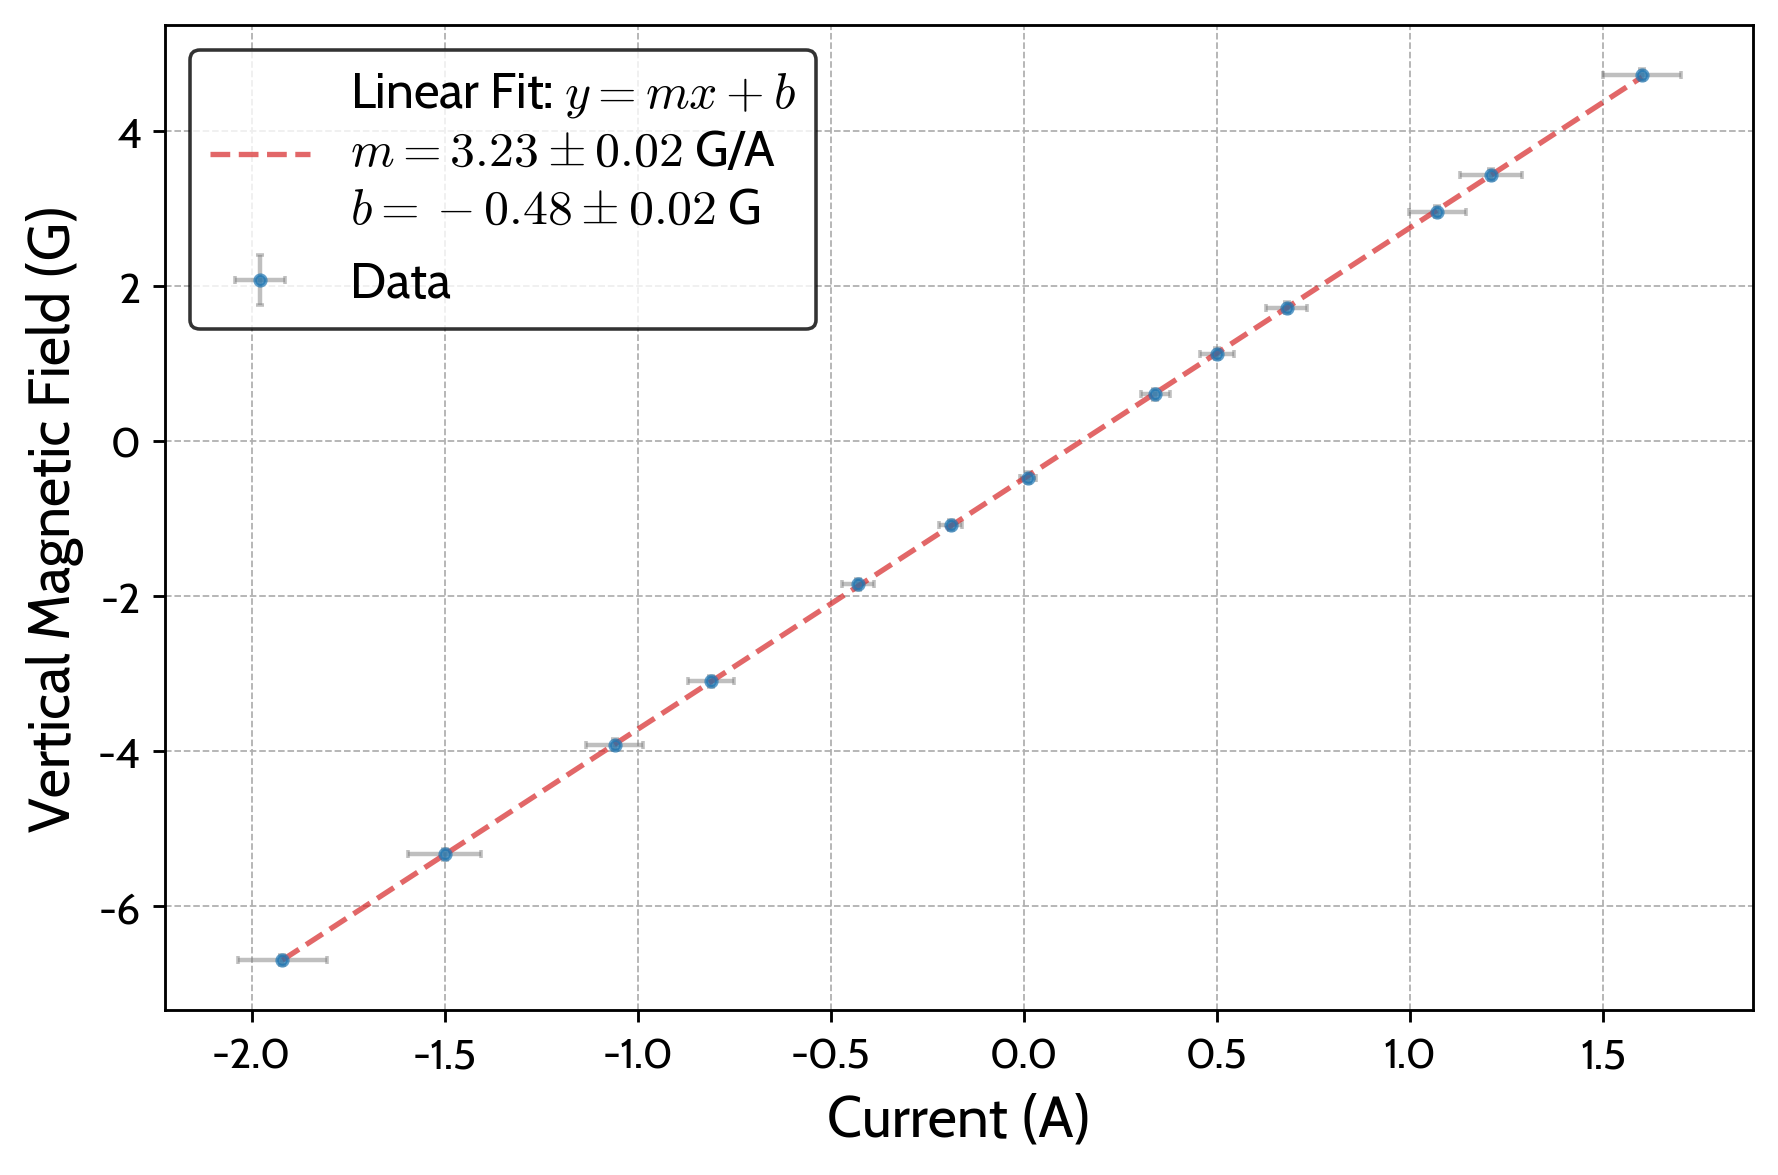

In [2]:
# vertical field coils calibration
current = np.array([0.01, 0.34, 0.5, 0.68, 1.07, 1.21, 1.60, -0.19, -0.43, -0.81, -1.06, -1.5, -1.92])
current_uncertainty = np.abs(current) * 0.05 + 0.02

field = np.array([-242, 295, 554, 851, 1466, 1706, 2346, -545, -927, -1550, -1957, -2661, -3340])
field_uncertainty = np.ones(len(field)) * 35

field = gaussmeter(field)
field_uncertainty = gaussmeter_uncertainty(field, field_uncertainty)

def f(x, m, b):
    return m * x + b

popt, pcov = curve_fit(f, current, field, sigma=field_uncertainty, absolute_sigma=True)
fit_uncertainty = np.sqrt(np.diag(pcov))

label = (
    f"Linear Fit: $y = mx + b$\n"
    f"$m = {popt[0]:.2f} \\pm {fit_uncertainty[0]:.2f}$ G/A\n"
    f"$b = {popt[1]:.2f} \\pm {fit_uncertainty[1]:.2f}$ G"
)

fig, ax = plt.subplots(figsize=(8, 5), dpi = 256)
markers, caps, bars = ax.errorbar(current, field, xerr=current_uncertainty, yerr=field_uncertainty, fmt='o', ms=3, ecolor='gray', alpha=0.7, elinewidth=1.25, capsize=1, label  = "Data")

ax.plot([current.min(), current.max()], f(np.array([current.min(), current.max()]), *popt), color = "tab:red", alpha = 0.7, linestyle = "--", label = label)

for cap in caps:
    cap.set_alpha(0.5)
for bar in bars:
    bar.set_alpha(0.5)
    
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.set_xlabel('Current (A)')
ax.set_ylabel('Vertical Magnetic Field (G)')
ax.legend()

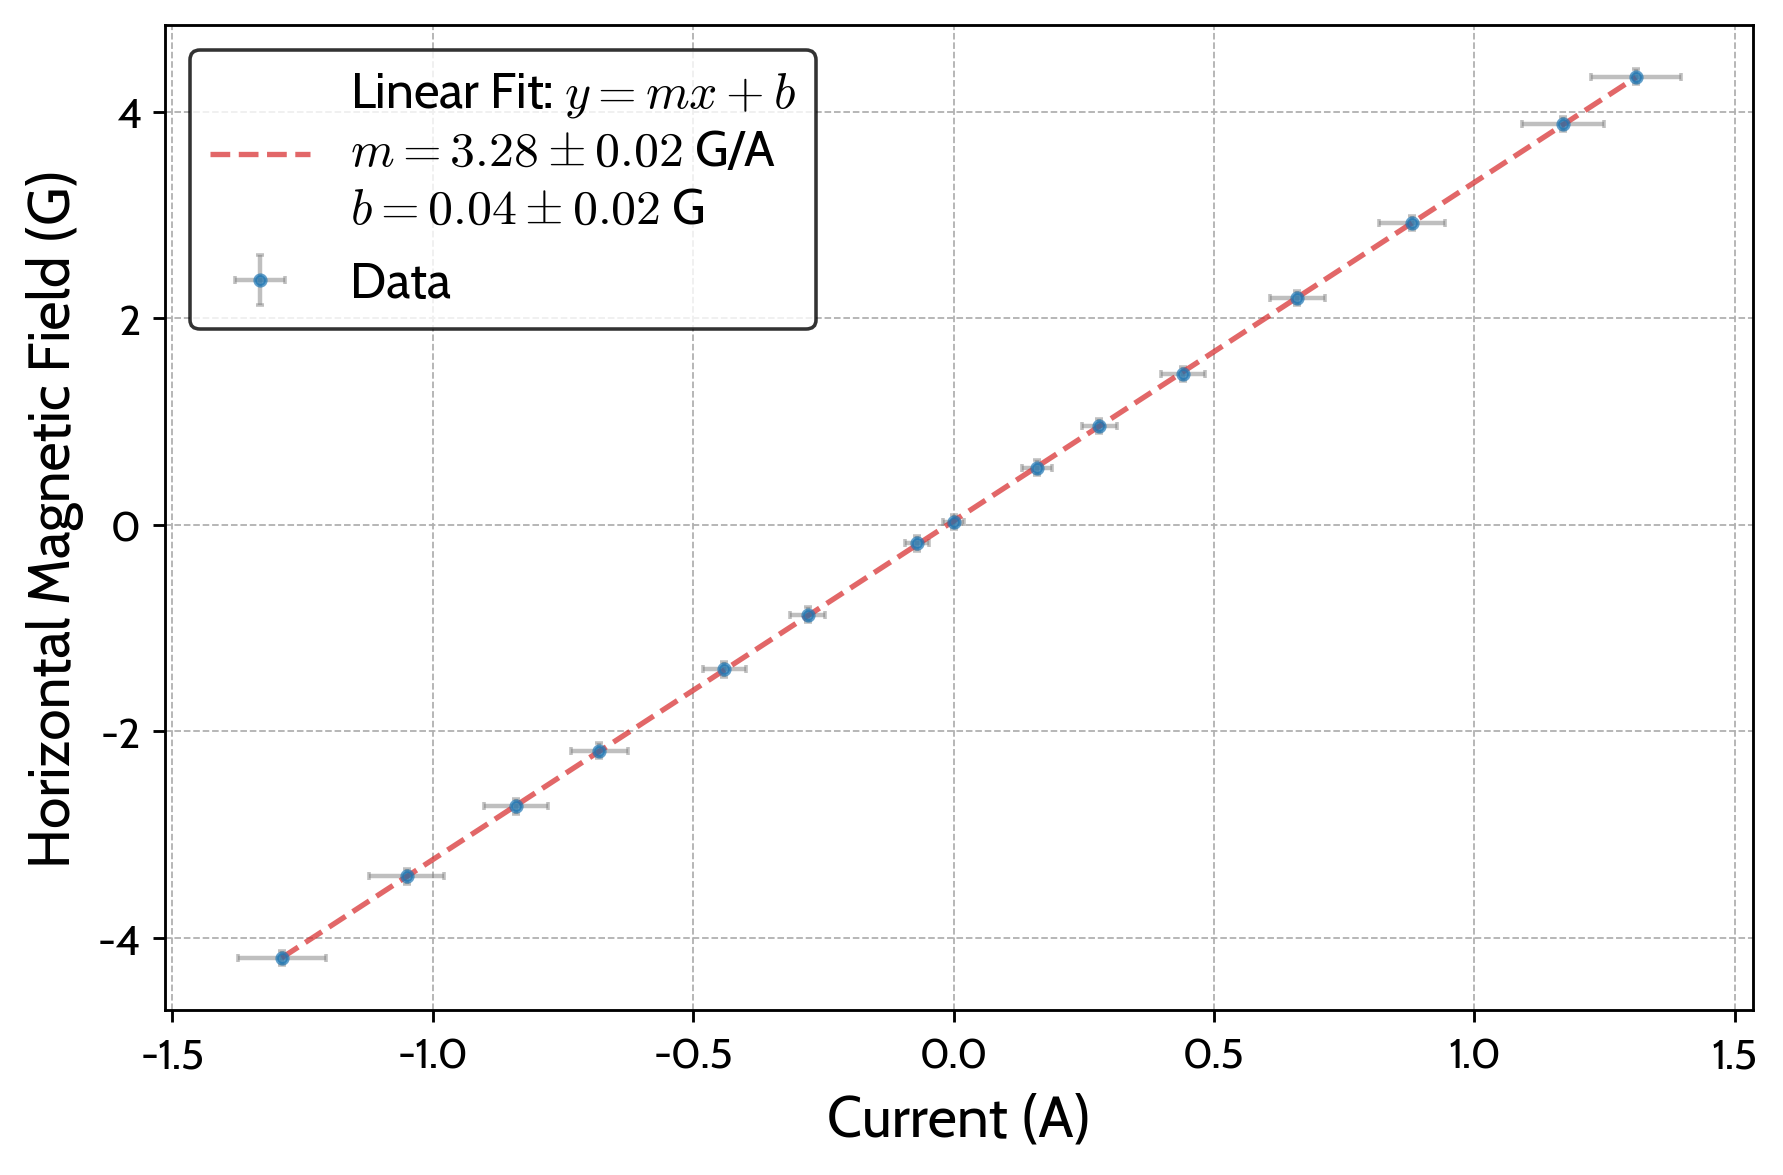

In [3]:
# horizontal field
current = np.array([0, 0.16, 0.28, 0.44, 0.66, 0.88, 1.17, 1.31, -1.29, -1.05, -0.84, -0.68, -0.44, -0.28, -0.07])
current_uncertainty = np.abs(current) * 0.05 + 0.02

field = np.array([8.8, 271, 472, 721, 1088, 1451, 1929, 2156, -2096, -1701, -1363, -1094, -703, -439, -95])
field_uncertainty = np.ones(len(field)) * 35

field = gaussmeter(field)
field_uncertainty = gaussmeter_uncertainty(field, field_uncertainty)

def f(x, m, b):
    return m * x + b

popt, pcov = curve_fit(f, current, field, sigma=field_uncertainty, absolute_sigma=True)
fit_uncertainty = np.sqrt(np.diag(pcov))

label = (
    f"Linear Fit: $y = mx + b$\n"
    f"$m = {popt[0]:.2f} \\pm {fit_uncertainty[0]:.2f}$ G/A\n"
    f"$b = {popt[1]:.2f} \\pm {fit_uncertainty[1]:.2f}$ G"
)

fig, ax = plt.subplots(figsize=(8, 5), dpi = 256)
markers, caps, bars = ax.errorbar(current, field, xerr=current_uncertainty, yerr=field_uncertainty, fmt='o', ms=3, ecolor='gray', alpha=0.7, elinewidth=1.25, capsize=1, label  = "Data")

ax.plot([current.min(), current.max()], f(np.array([current.min(), current.max()]), *popt), color = "tab:red", alpha = 0.7, linestyle = "--", label = label)

for cap in caps:
    cap.set_alpha(0.5)
for bar in bars:
    bar.set_alpha(0.5)
    
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.set_xlabel('Current (A)')
ax.set_ylabel('Horizontal Magnetic Field (G)')
ax.legend()

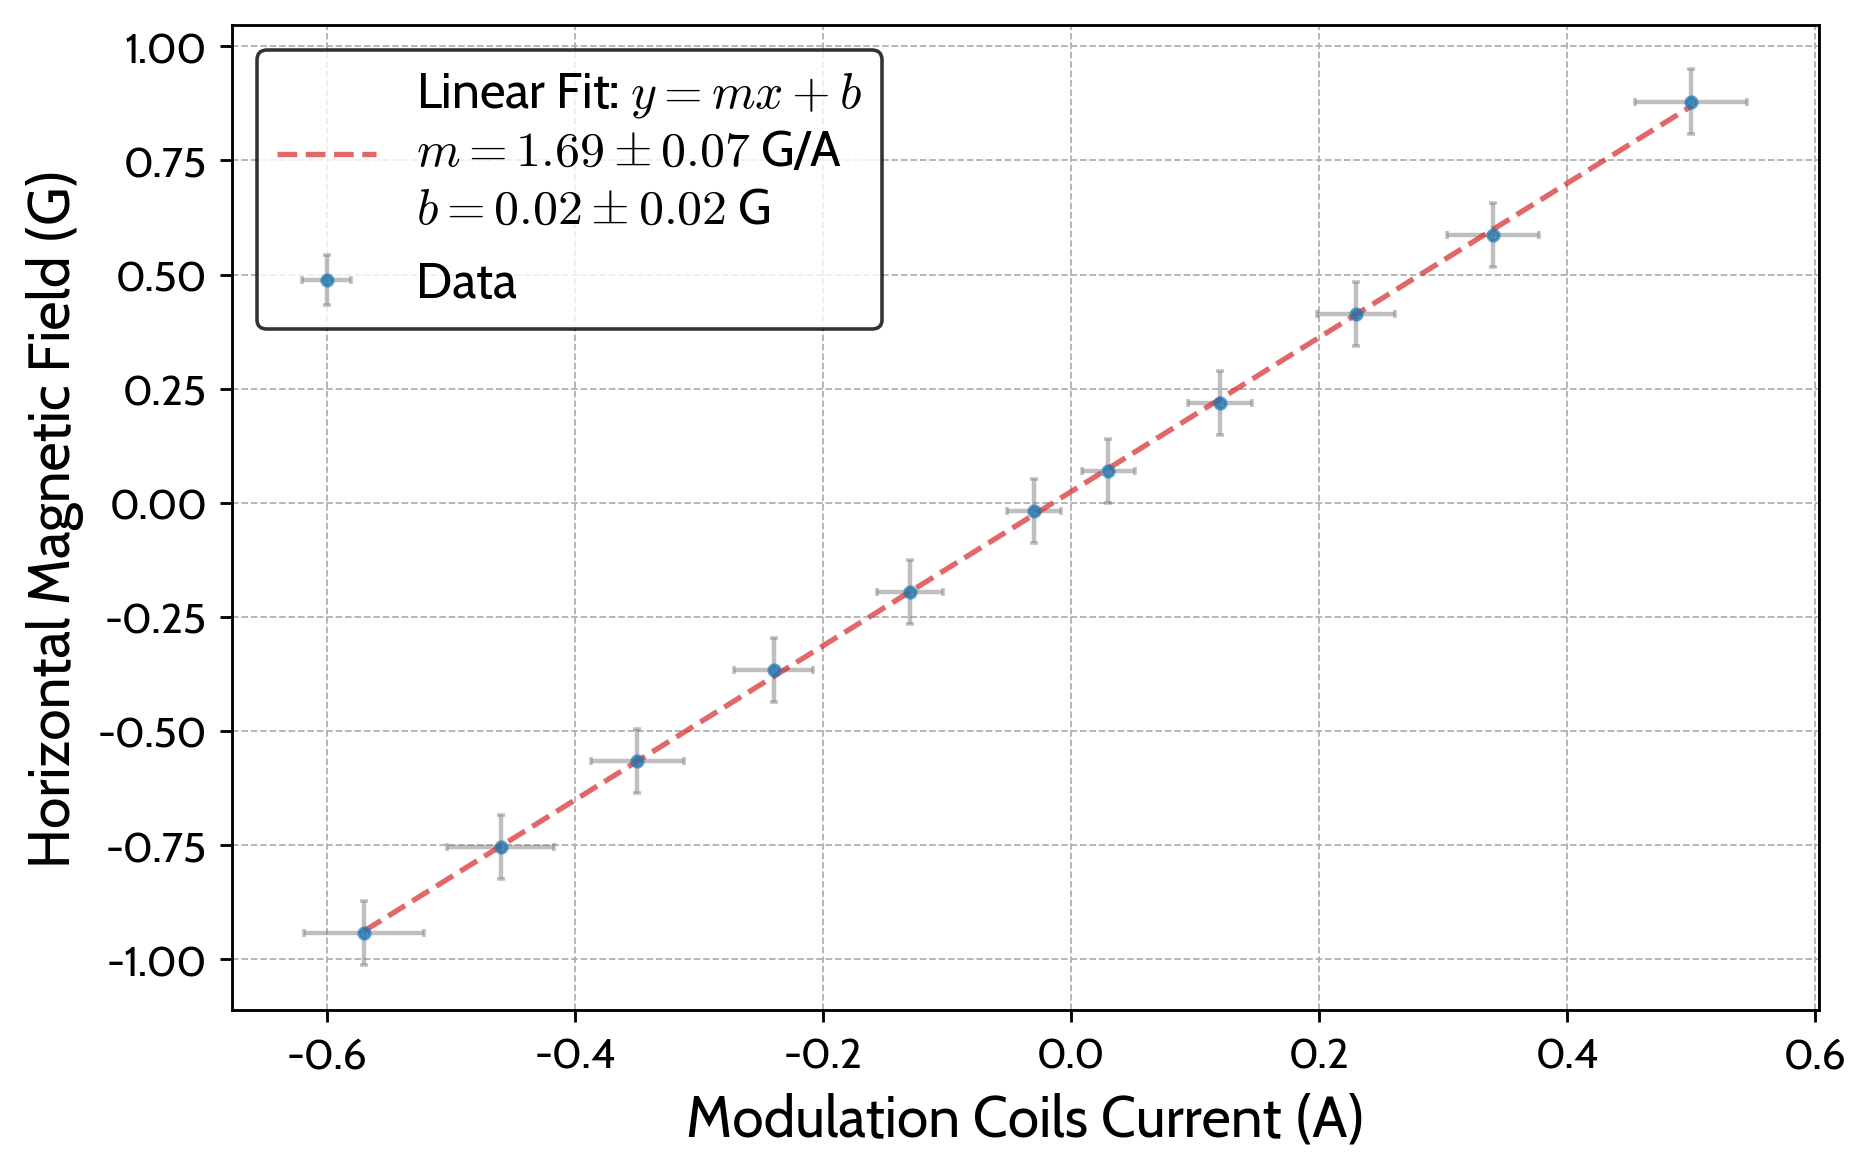

In [4]:
# modulation field
current = np.array([0.03, 0.12, 0.23, 0.34, 0.5, -0.03, -0.13, -0.24, -0.35, -0.46, -0.57])
current_uncertainty = np.abs(current) * 0.05 + 0.02

field = np.array([30, 104, 201, 287, 433, -14.2, -102, -187, -287, -381, -475])
field_uncertainty = np.ones(len(field)) * 35

field = gaussmeter(field)
field_uncertainty = gaussmeter_uncertainty(field, field_uncertainty)

def f(x, m, b):
    return m * x + b

popt, pcov = curve_fit(f, current, field, sigma=field_uncertainty, absolute_sigma=True)
fit_uncertainty = np.sqrt(np.diag(pcov))

label = (
    f"Linear Fit: $y = mx + b$\n"
    f"$m = {popt[0]:.2f} \\pm {fit_uncertainty[0]:.2f}$ G/A\n"
    f"$b = {popt[1]:.2f} \\pm {fit_uncertainty[1]:.2f}$ G"
)

fig, ax = plt.subplots(figsize=(8, 5), dpi = 256)
markers, caps, bars = ax.errorbar(current, field, xerr=current_uncertainty, yerr=field_uncertainty, fmt='o', ms=3, ecolor='gray', alpha=0.7, elinewidth=1.25, capsize=1, label  = "Data")

ax.plot([current.min(), current.max()], f(np.array([current.min(), current.max()]), *popt), color = "tab:red", alpha = 0.7, linestyle = "--", label = label)

for cap in caps:
    cap.set_alpha(0.5)
for bar in bars:
    bar.set_alpha(0.5)

ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.set_xlabel('Modulation Coils Current (A)')
ax.set_ylabel('Horizontal Magnetic Field (G)')
ax.legend()

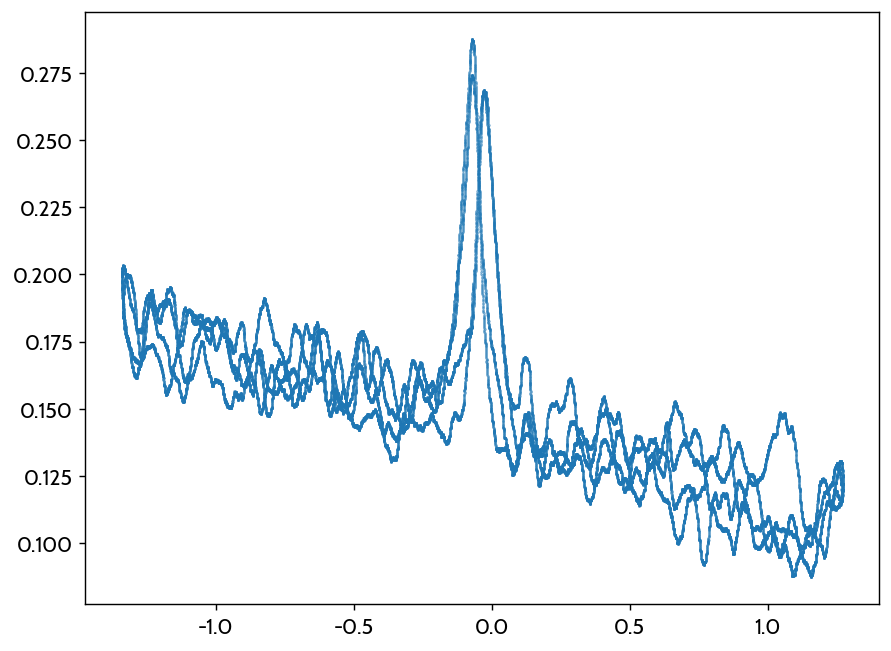

In [5]:
# horizontal field sweep (forgot to zero the vertical field)
t, V1, V2, V3 = np.loadtxt("data/16/scope_4.csv", delimiter=",", unpack=True, skiprows = 2)

# smooth data
N = 200
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig, ax = plt.subplots(figsize=(8, 6), dpi = 128)
# ax.plot(t, V1, label='Channel 1', color='tab:blue')
# ax.plot(t, V2, label='Channel 2', color='tab:orange')
# ax.plot(t, V3, label='Channel 3', color='tab:green')

ax.plot(V1, V2, 'o', markersize=0.5, alpha=0.5, label='Channel 1 vs Channel 2')


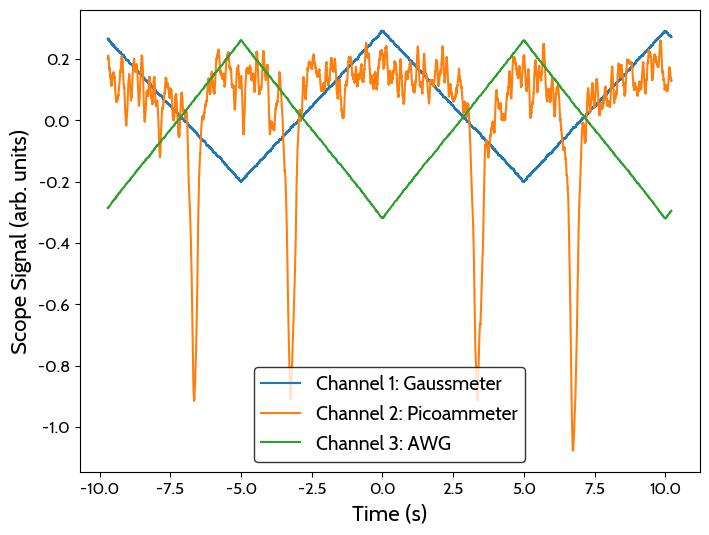

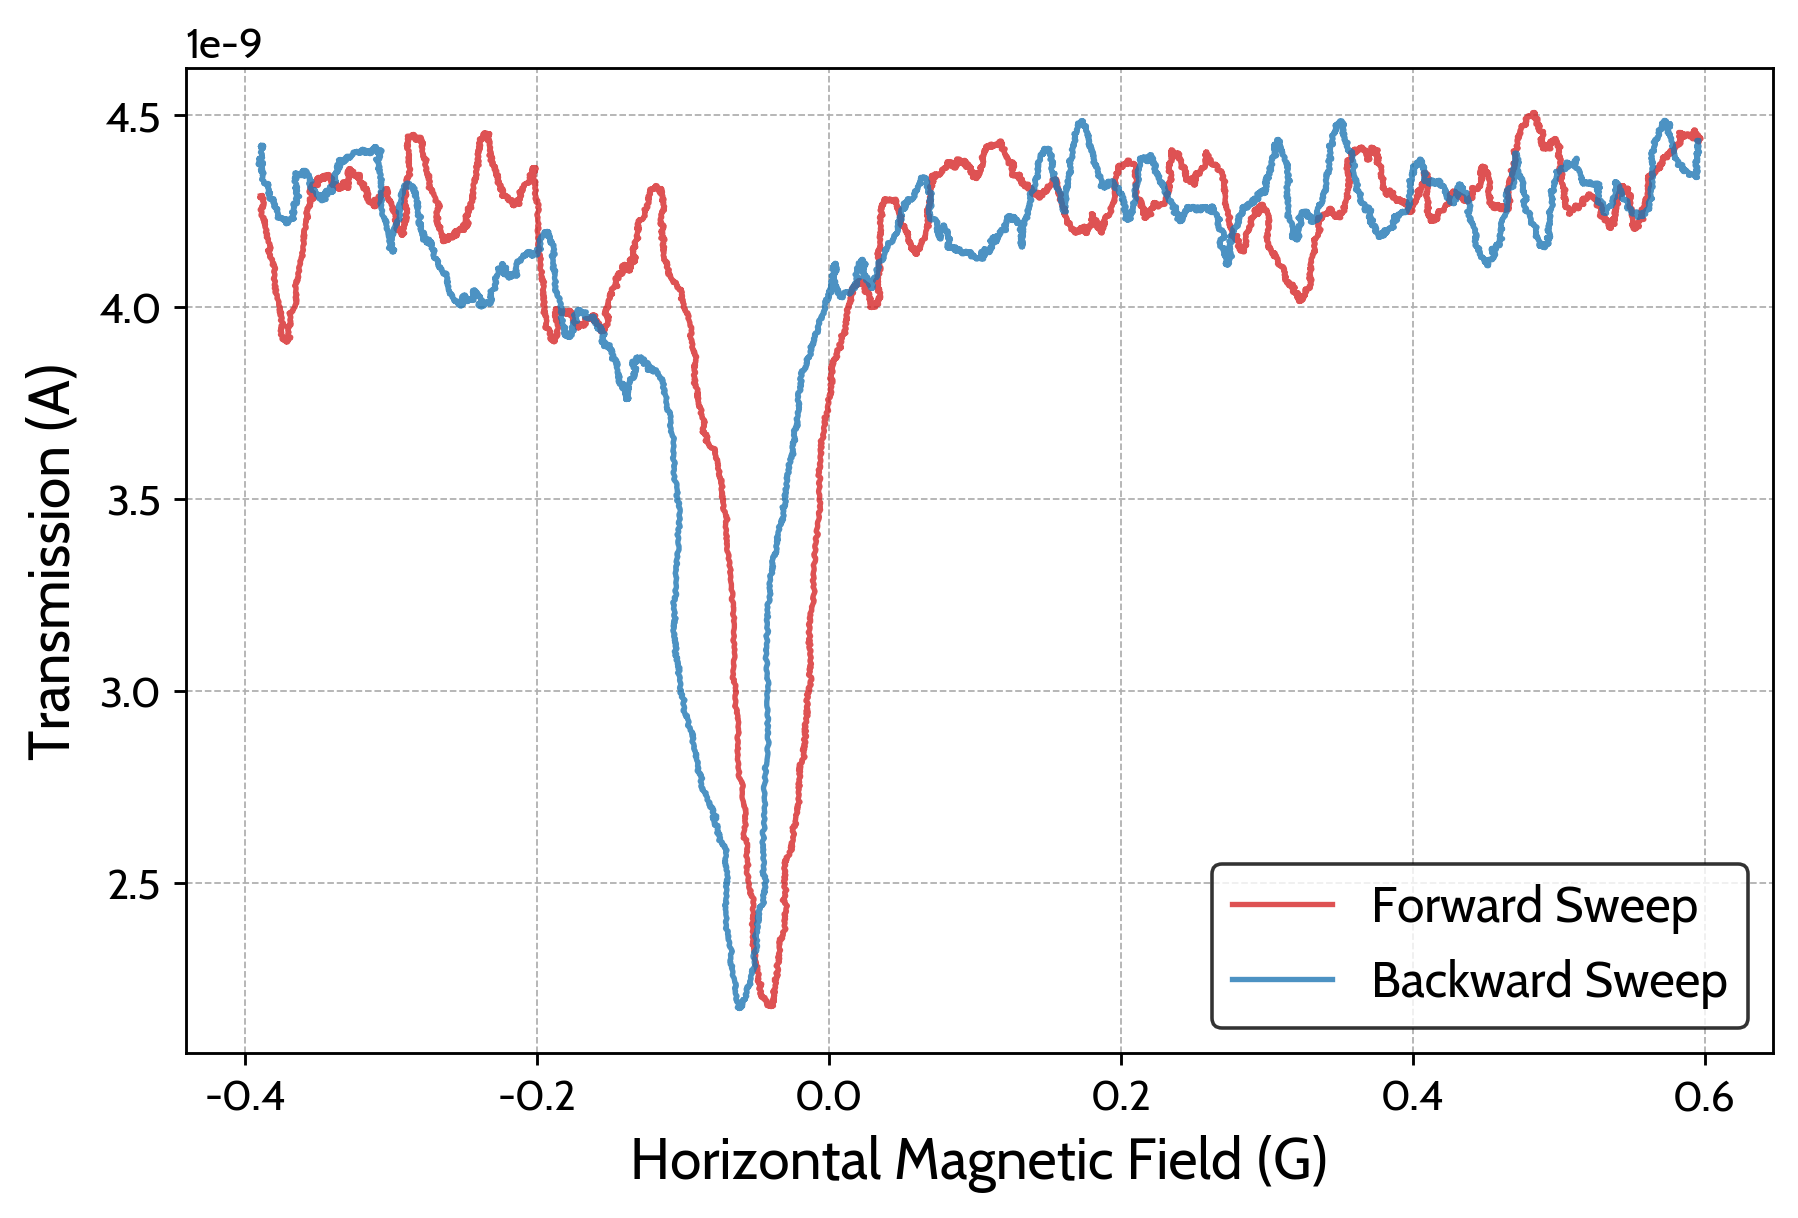

In [6]:
# horizontal field sweep (with vertical field zeroed)
t, V1, V2, V3 = np.loadtxt("data/16/scope_3.csv", delimiter=",", unpack=True, skiprows = 2)


N = 200
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# forward
mask = (t > -5) & (t < 0)
transmission_forward = ammeter(V2[mask]*1e3)
field_forward = gaussmeter(V1[mask]*1e3)

#backward
mask = (t > 0) & (t < 5)
transmission_backward = ammeter(V2[mask]*1e3)
field_backward = gaussmeter(V1[mask]*1e3)

fig, ax = plt.subplots(figsize=(8, 5), dpi = 256)

ax.plot(field_forward, transmission_forward, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_backward, transmission_backward, label='Backward Sweep', color='tab:blue', alpha = 0.8)

ax.set_xlabel('Horizontal Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()

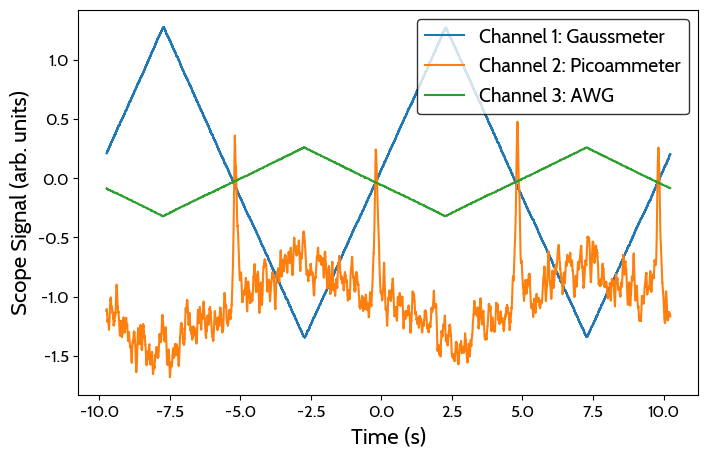

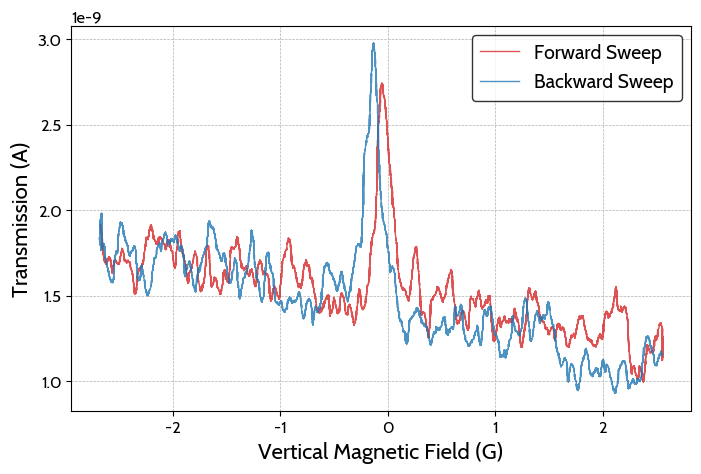

In [7]:
# vertical field sweep (with horizontal field zeroed)
t, V1, V2, V3 = np.loadtxt("data/16/scope_4.csv", delimiter=",", unpack=True, skiprows = 2)


N = 100
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')
V3 = np.convolve(V3, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 5))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*10-2.5, label='Channel 2: Picoammeter', color='tab:orange')
ax0.plot(t, V3, label='Channel 3: AWG', color='tab:green')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

#forward
mask = (t > -2.7) & (t < 2.3)
field_forward = gaussmeter(V1[mask]*1e3)
transmission_forward = ammeter(V2[mask]*1e3)
#backward
mask = (t > 2.3) & (t < 7.3)
field_backward = gaussmeter(V1[mask]*1e3)
transmission_backward = ammeter(V2[mask]*1e3)

#combined
sort_indices = np.argsort(field_forward)
field_forward = field_forward[sort_indices]
transmission_forward = transmission_forward[sort_indices]
sort_indices = np.argsort(field_backward)
field_backward = field_backward[sort_indices]
transmission_backward = transmission_backward[sort_indices]

field = field_forward
transmission = np.mean([transmission_forward, transmission_backward], axis=0)


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(field_forward, transmission_forward, lw = 1, label='Forward Sweep', color='tab:red', alpha = 0.8)
ax.plot(field_backward, transmission_backward, lw = 1, label='Backward Sweep', color='tab:blue', alpha = 0.8)
# ax.plot(field, transmission, label='Average', lw = 0.5, color='k', alpha = 0.7)

ax.set_xlabel('Vertical Magnetic Field (G)')
ax.set_ylabel('Transmission (A)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
ax.legend()



In [8]:
%matplotlib ipympl

In [9]:
2.5*2/(0.4+0.7)

4.545454545454545